<a href="https://colab.research.google.com/github/Endoefa/ovo/blob/main/Tutorial_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import libraries, packages and modules

In [ ]:
from skimage.feature import local_binary_pattern   # import the local_binary_pattern() function from skimage library
from skimage import data              # for more information about the skimage please visit https://scikit-image.org/
from skimage.color import label2rgb        # function importing. see comments below
import matplotlib.pyplot as plt         # ...
import numpy as np               # ...

# Set parameters for LBP
For more information, please watch the lecture recordings or find the definitions in this paper https://www.researchgate.net/publication/331541161_Circular_Derivative_Local_Binary_Pattern_Feature_Description_for_Facial_Expression_Recognition

In [ ]:
# 设置 LBP 参数；详细定义可参考课程录屏或上方论文
radius = 3  # 设置 LBP 圆形邻域的半径
n_points = 8 * radius  # 设置圆形邻域内采样点的数量；这里半径为 3，因此采样 24 个点

# Define functions for later use
The following codes defines a function which can mark the area with certain features

In [ ]:
def overlay_labels(image, lbp, labels):
    # 对每个指定标签分别比较，得到一组布尔矩阵；True 表示该位置的 LBP 值等于对应标签
    # 将这些布尔矩阵按逻辑“或”合并，得到包含所有目标标签区域的掩膜
    mask = np.logical_or.reduce([lbp == each for each in labels])

    # 可取消下一行注释，查看每个标签分别对应的布尔矩阵
    # print([lbp == each for each in labels])

    # 将掩膜以半透明方式叠加到原图上；bg_label=0 表示标签 0 作为背景
    return label2rgb(mask, image=image, bg_label=0, alpha=0.5)

The function below is defined to color all selected bars red, it intake the bar chart object and the indexes of bars which you want to color

In [ ]:
def highlight_bars(bars, indexes):
    # 逐个取出指定索引对应的柱子，并将填充颜色设为红色
    for i in indexes:
        bars[i].set_facecolor('r')

This following function is defined to draw a histogram of a LBP feature map

In [ ]:
def hist(ax, lbp):
    # LBP 特征值是离散整数；最大特征值加 1，作为直方图的柱子数量
    n_bins = int(lbp.max() + 1)

    # 将二维特征图展平成一维数组后绘制直方图
    # density=True 表示纵轴显示归一化后的比例密度
    return ax.hist(
        lbp.ravel(),
        density=True,
        bins=n_bins,
        range=(0, n_bins),
        facecolor='0.5'
    )

# Read an image and calculate the LPB feature
Start to study the code for this week from this chapter

In [ ]:
image = data.brick()  # 从 scikit-image 的示例数据中读取砖墙图像
plt.imshow(image, cmap='gray')  # 以灰度色图显示原始图像

# 计算图像的 LBP 特征图：使用 n_points 个邻域采样点、半径 radius 和 uniform 模式
lbp = local_binary_pattern(image, n_points, radius, 'uniform')

# Show visualised LPB feature显示并分析 LBP 特征

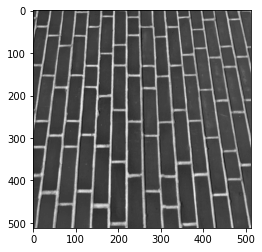

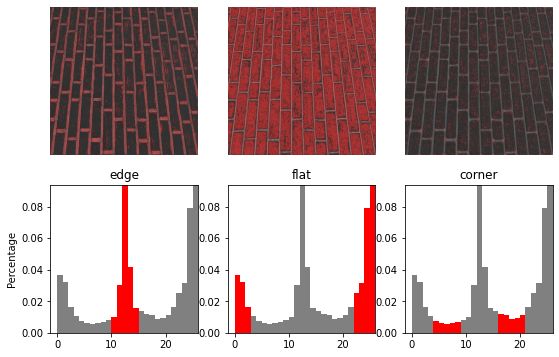

In [ ]:
# 创建 2 行 3 列的子图：上排显示不同类别的图像区域，下排显示对应直方图
fig, (ax_img, ax_hist) = plt.subplots(nrows=2, ncols=3, figsize=(9, 6))
plt.gray()  # 将默认色图设为灰度

# 三类 LBP 特征的显示标题
titles = ('edge', 'flat', 'corner')

# 根据半径设置分类范围的宽度
w = width = radius - 1

# 选出被视为边缘特征的 LBP 标签
edge_labels = range(n_points // 2 - w, n_points // 2 + w + 1)

# 选出被视为平坦区域特征的 LBP 标签；标签范围可能跨越编码序列首尾，因此分两段表示
flat_labels = list(range(0, w + 1)) + list(range(n_points - w, n_points + 2))

# 计算直方图中约 1/4 和 3/4 位置，用于选出角点特征标签
i_14 = n_points // 4
i_34 = 3 * (n_points // 4)
corner_labels = (
    list(range(i_14 - w, i_14 + w + 1)) +
    list(range(i_34 - w, i_34 + w + 1))
)

# 将三类特征对应的标签集合放在一起，便于后续循环处理
label_sets = (edge_labels, flat_labels, corner_labels)

# 依次在上排三个子图中叠加显示边缘、平坦区域和角点对应的位置
for ax, labels in zip(ax_img, label_sets):
    ax.imshow(overlay_labels(image, lbp, labels))

# 依次绘制三类特征的直方图，并将对应标签的柱子标成红色
for ax, labels, name in zip(ax_hist, label_sets, titles):
    counts, _, bars = hist(ax, lbp)  # 绘制 LBP 直方图，保存柱高和柱状图对象
    highlight_bars(bars, labels)  # 将当前类别对应的柱子标红

    # 调整纵轴上限，避免最高柱超出显示范围；counts[:-1] 排除最后一个额外统计项
    ax.set_ylim(top=np.max(counts[:-1]))

    # 将横轴范围限制到 LBP 标签范围附近
    ax.set_xlim(right=n_points + 2)
    ax.set_title(name)  # 设置当前直方图标题

# 给下排第一个直方图添加纵轴标签
ax_hist[0].set_ylabel('Percentage')

# 隐藏上排图像的坐标轴刻度和边框
for ax in ax_img:
    ax.axis('off')